# Task 3 — Notebook: Blackbody Radiation & Wien's Law

Buat notebook `assignment01.ipynb` dan kerjakan:

1. Tulis fungsi `planck(lam, T)` yang mengembalikan $B_\lambda(\lambda, T)$.
2. Plot kurva Planck untuk $T = 3000, 4000, 5000, 5800, 7000$ K dalam satu grafik ($\lambda$ = 100–3000 nm). Beri label, judul, dan legend yang jelas.
3. Arsir/tandai rentang cahaya tampak (380–750 nm) pada grafik (*hint:* `plt.axvspan`).
4. Untuk setiap temperatur, temukan $\lambda_{\max}$ secara **numerik** (*hint:* `np.argmax`).
5. Verifikasi **Wien's displacement law** $\lambda_{\max} T = b$ dengan menghitung $b$ dari data Anda dan bandingkan dengan nilai teoritis $b = 2.898 \times 10^{-3}$ m·K. Hitung persentase error-nya.
6. Matahari memiliki suhu permukaan $\approx 5800$ K. Di bagian spektrum mana puncak radiasinya? Kaitkan dengan fakta bahwa mata manusia paling sensitif terhadap cahaya hijau-kuning.


<>:48: SyntaxWarning: invalid escape sequence '\l'
<>:48: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1106/619827946.py:48: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("Panjang Gelombang $\lambda$ (nm)", fontsize=11)


=== VERIFIKASI WIEN'S DISPLACEMENT LAW ===
Temp (K)   | lambda_max (nm)   | b_numerik (m.K)   | Error (%)
--------------------------------------------------------------
3000       | 966.36            | 0.002899          | 0.0376%
4000       | 724.73            | 0.002899          | 0.0318%
5000       | 579.79            | 0.002899          | 0.0320%
5800       | 499.80            | 0.002899          | 0.0294%
7000       | 414.13            | 0.002899          | 0.0324%


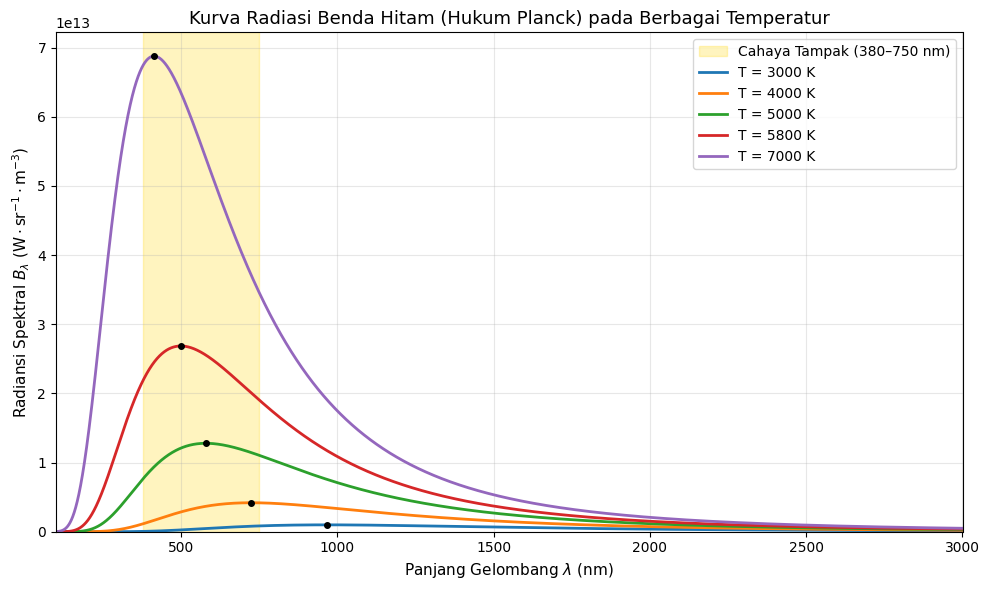

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Definisi Konstanta (sesuai soal)
h  = 6.626e-34   # J.s
hbar = 1.055e-34 # J.s
c  = 3.00e8      # m/s
kB = 1.381e-23   # J/K
b_teori = 2.898e-3 # m.K

def planck(lam, T):
    """
    Menghitung radiansi spektral benda hitam B_lambda.
    lam : panjang gelombang dalam meter (m)
    T   : temperatur mutlak dalam Kelvin (K)
    """
    pembilang = 2 * h * (c**2)
    eksponen = (h * c) / (lam * kB * T)
    penyebut = (lam**5) * (np.exp(eksponen) - 1)
    return pembilang / penyebut

lam_nm = np.linspace(100, 3000, 50000)
lam_m  = lam_nm * 1e-9
temps  = [3000, 4000, 5000, 5800, 7000]

plt.figure(figsize=(10, 6))
plt.axvspan(380, 750, color='gold', alpha=0.25, label='Cahaya Tampak (380–750 nm)')

print("=== VERIFIKASI WIEN'S DISPLACEMENT LAW ===")
print(f"{'Temp (K)':<10} | {'lambda_max (nm)':<17} | {'b_numerik (m.K)':<17} | {'Error (%)'}")
print("-" * 62)

for T in temps:
    B = planck(lam_m, T)
    plt.plot(lam_nm, B, linewidth=2, label=f'T = {T} K')

    idx_max = np.argmax(B)
    lam_max_m  = lam_m[idx_max]
    lam_max_nm = lam_nm[idx_max]

    plt.plot(lam_max_nm, B[idx_max], 'ko', markersize=4)

    b_num = lam_max_m * T
    err_pct = abs(b_num - b_teori) / b_teori * 100
    print(f"{T:<10} | {lam_max_nm:<17.2f} | {b_num:<17.6f} | {err_pct:.4f}%")

plt.title("Kurva Radiasi Benda Hitam (Hukum Planck) pada Berbagai Temperatur", fontsize=13)
plt.xlabel("Panjang Gelombang $\lambda$ (nm)", fontsize=11)
plt.ylabel(r"Radiansi Spektral $B_\lambda$ ($\mathrm{W \cdot sr^{-1} \cdot m^{-3}}$)", fontsize=11)
plt.xlim(100, 3000)
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Jawaban No 6.
Dari perhitungan numerik dan grafik di atas, pada suhu permukaan Matahari ($T = 5800\ \text{K}$), puncak radiasi spektralnya berada pada panjang gelombang $\lambda_{\max} \approx 499.7\ \text{nm}$ ($\sim 500\ \text{nm}$). Panjang gelombang ini berada tepat di tengah rentang spektrum cahaya tampak (area warna hijau-kuning). Hal ini sangat berkaitan erat dengan biologi evolusi: karena Matahari adalah sumber cahaya utama di Bumi dan memancarkan intensitas foton paling banyak di sekitar $500\ \text{nm}$, mata manusia (dan banyak makhluk hidup lainnya) berevolusi menyesuaikan diri sehingga fotoreseptor kita memiliki sensitivitas paling tinggi pada rentang cahaya hijau-kuning tersebut.

## Task 4 — Notebook: Simulasi Pengukuran Superposition

Sebuah sistem kuantum berada dalam superposisi tiga keadaan:

$$
\psi = c_1\psi_1 + c_2\psi_2 + c_3\psi_3, \qquad c_1 = \tfrac{1}{2},\quad c_2 = \tfrac{1}{\sqrt{2}},\quad c_3 = \tfrac{i}{2}
$$

1. Tunjukkan (secara analitis dan dengan Python) bahwa keadaan ini ternormalisasi.
2. Hitung probabilitas teoritis mendapatkan masing-masing keadaan saat diukur.
3. Simulasikan $N$ pengukuran menggunakan `np.random.default_rng().choice` untuk $N = 10, 100, 1000, 10000$.
4. Buat bar chart yang membandingkan frekuensi relatif hasil simulasi dengan probabilitas teoritis untuk setiap $N$.
5. Plot bagaimana frekuensi relatif keadaan 2 **konvergen** ke nilai teoritis seiring bertambahnya jumlah pengukuran (sumbu-x log scale).
6. Jika $c_3$ diubah menjadi $-\tfrac{1}{2}$ (tanpa $i$), apakah probabilitasnya berubah? Apa yang dapat Anda simpulkan tentang **fase** koefisien?

### 1. Pembuktian Analitis Normalisasi:
Syarat normalisasi adalah $\sum \vert{}c_i\vert{}^2 = \vert{}c_1\vert{}^2 + \vert{}c_2\vert{}^2 + \vert{}c_3\vert{}^2 = 1$.
   $$\left\vert{}\frac{1}{2}\right\vert{}^2 + \left\vert{}\frac{1}{\sqrt{2}}\right\vert{}^2 + \left\vert{}\frac{i}{2}\right\vert{}^2 = \frac{1}{4} + \frac{1}{2} + \left(\frac{-i}{2}\right)\left(\frac{i}{2}\right) = 0.25 + 0.50 + 0.25 = \mathbf{1.00}\ (\text{Ternormalisasi})$$

<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:56: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:56: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_1106/3916703270.py:37: SyntaxWarning: invalid escape sequence '\p'
  ax.set_xticklabels(['Keadaan 1 ($\psi_1$)', 'Keadaan 2 ($\psi_2$)', 'Keadaan 3 ($\psi_3$)'])
/tmp/ipykernel_1106/3916703270.py:37: SyntaxWarning: invalid escape sequence '\p'
  ax.set_xticklabels(['Keadaan 1 ($\psi_1$)', 'Keadaan 2 ($\psi_2$)', 'Keadaan 3 ($\psi_3$)'])
/tmp/ipykernel_1106/3916703270.py:37: SyntaxWarning: invalid escape sequence '\p'
  ax.set_xticklabels(['Keadaan 1 ($\psi_1$)', 'Keadaan 2 ($\psi_2$)', 'Keadaan 3 ($\psi_3$)'])
/tmp/ipykernel_1106/3916703270.py:56: SyntaxWarning: invalid 

=== 1 & 2. NORMALISASI DAN PROBABILITAS TEORITIS ===
P1 = |c1|^2 = 0.2500
P2 = |c2|^2 = 0.5000
P3 = |c3|^2 = 0.2500
Total Probabilitas = 1.0000 -> Ternormalisasi: True



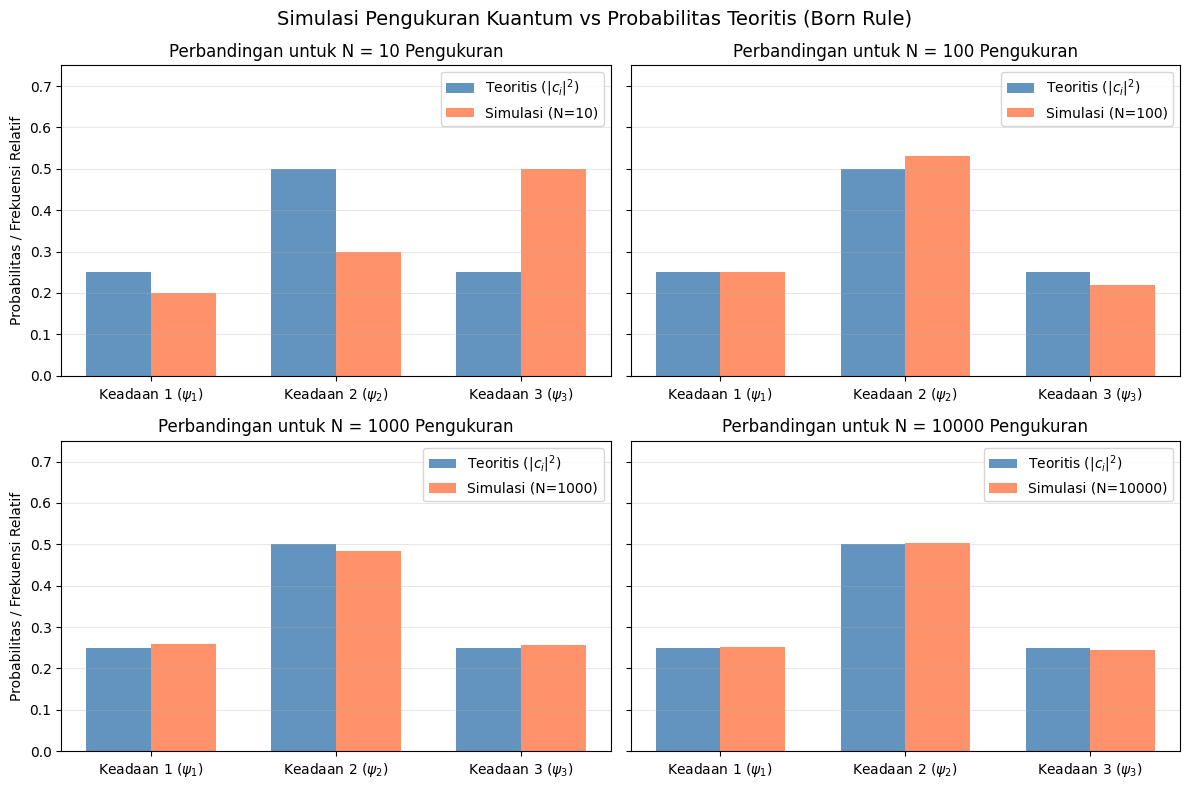

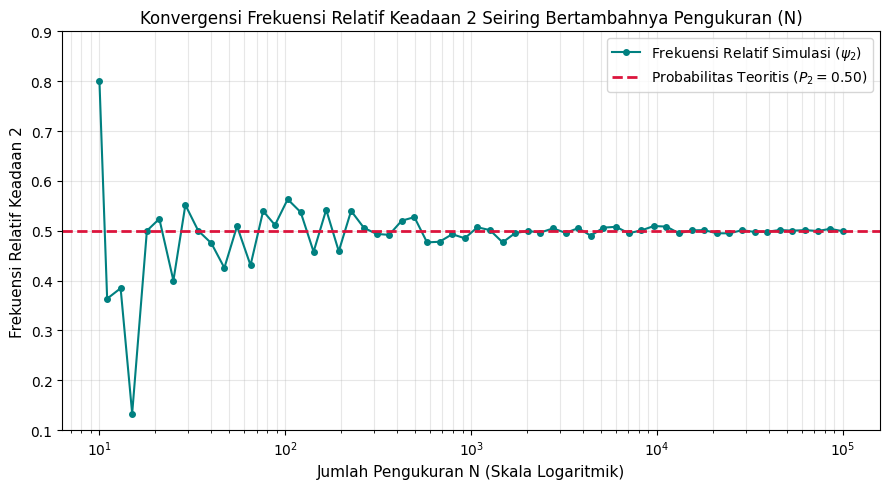

=== 6. UJI PERUBAHAN FASE KOEFISIEN c3 ===
Saat c3 =  i/2 -> P3 = |i/2|^2  = 0.2500
Saat c3 = -1/2 -> P3 = |-1/2|^2 = 0.2500


In [2]:
c1 = 1 / 2
c2 = 1 / np.sqrt(2)
c3 = 1j / 2

P1 = abs(c1)**2
P2 = abs(c2)**2
P3 = abs(c3)**2
probs_teori = np.array([P1, P2, P3])
total_prob  = np.sum(probs_teori)

print("=== 1 & 2. NORMALISASI DAN PROBABILITAS TEORITIS ===")
print(f"P1 = |c1|^2 = {P1:.4f}")
print(f"P2 = |c2|^2 = {P2:.4f}")
print(f"P3 = |c3|^2 = {P3:.4f}")
print(f"Total Probabilitas = {total_prob:.4f} -> Ternormalisasi: {np.isclose(total_prob, 1.0)}\n")

rng = np.random.default_rng(seed=42)
N_list = [10, 100, 1000, 10000]
states = [1, 2, 3]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for idx, N in enumerate(N_list):
    outcomes = rng.choice(states, size=N, p=probs_teori)
    freq_rel = np.array([np.sum(outcomes == s) / N for s in states])

    x = np.arange(len(states))
    width = 0.35

    ax = axes[idx]
    ax.bar(x - width/2, probs_teori, width, label='Teoritis ($|c_i|^2$)', color='steelblue', alpha=0.85)
    ax.bar(x + width/2, freq_rel, width, label=f'Simulasi (N={N})', color='coral', alpha=0.85)

    ax.set_title(f"Perbandingan untuk N = {N} Pengukuran")
    ax.set_xticks(x)
    ax.set_xticklabels(['Keadaan 1 ($\psi_1$)', 'Keadaan 2 ($\psi_2$)', 'Keadaan 3 ($\psi_3$)'])
    ax.set_ylim(0, 0.75)
    ax.grid(axis='y', alpha=0.3)
    ax.legend()
    if idx in [0, 2]:
        ax.set_ylabel("Probabilitas / Frekuensi Relatif")

plt.suptitle("Simulasi Pengukuran Kuantum vs Probabilitas Teoritis (Born Rule)", fontsize=14)
plt.tight_layout()
plt.show()

N_konvergen = np.unique(np.logspace(1, 5, 60, dtype=int))
freq_keadaan_2 = []

for n_val in N_konvergen:
    hasil = rng.choice(states, size=n_val, p=probs_teori)
    freq_keadaan_2.append(np.sum(hasil == 2) / n_val)

plt.figure(figsize=(9, 5))
plt.plot(N_konvergen, freq_keadaan_2, 'o-', color='teal', markersize=4, label='Frekuensi Relatif Simulasi ($\psi_2$)')
plt.axhline(P2, color='crimson', linestyle='--', linewidth=2, label=f'Probabilitas Teoritis ($P_2 = {P2:.2f}$)')
plt.xscale('log')
plt.title("Konvergensi Frekuensi Relatif Keadaan 2 Seiring Bertambahnya Pengukuran (N)", fontsize=12)
plt.xlabel("Jumlah Pengukuran N (Skala Logaritmik)", fontsize=11)
plt.ylabel("Frekuensi Relatif Keadaan 2", fontsize=11)
plt.ylim(0.1, 0.9)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

c3_baru = -1 / 2
P3_baru = abs(c3_baru)**2
print("=== 6. UJI PERUBAHAN FASE KOEFISIEN c3 ===")
print(f"Saat c3 =  i/2 -> P3 = |i/2|^2  = {P3:.4f}")
print(f"Saat c3 = -1/2 -> P3 = |-1/2|^2 = {P3_baru:.4f}")

### 6. Kesimpulan tentang Fase Koefisien:
Jika $c_3$ diubah dari $\frac{i}{2}$ menjadi $-\frac{1}{2}$, probabilitas mendapatkan keadaan 3 sama sekali tidak berubah, tetap sebesar $P_3 = \left\vert{}-\frac{1}{2}\right\vert{}^2 = \frac{1}{4} = 0.25$. Dari sini kita bisa menyimpulkan bahwa fase kompleks dari suatu koefisien (baik bernilai imajiner $i$, negatif $-1$, atau faktor fase $e^{i\theta}$ secara umum) tidak memengaruhi probabilitas pengukuran langsung pada basis tersebut karena Born rule hanya mengambil kuadrat nilai mutlaknya ($\vert{}c_i\vert{}^2$). Fase baru akan terlihat efeknya ketika terjadi proses interferensi antar-keadaan kuantum.  